    done in 3s

  ── ROW 1: Single-Model Baselines ──

  [V1] Baseline — XGB + RF + LGB  (equal average)


    AUC=0.9378  Sens=0.9645  Spec=0.6750  BalAcc=0.8198  Brier=0.0817

  [V2] XGBoost only
    AUC=0.9452  Sens=0.9504  Spec=0.7750  BalAcc=0.8627  Brier=0.0742

  [V3] RandomForest only


    AUC=0.9285  Sens=0.9787  Spec=0.4250  BalAcc=0.7019  Brier=0.0982

  [V4] LightGBM only  (NEW)
    AUC=0.9301  Sens=0.9362  Spec=0.7250  BalAcc=0.8306  Brier=0.0832

  ── ROW 2: Two-Model Combinations ──



  [V5] XGB + LGB  (no RF)
    AUC=0.9381  Sens=0.9433  Spec=0.7250  BalAcc=0.8341  Brier=0.0780

  [V6] XGB + RF  (no LGB)


    AUC=0.9397  Sens=0.9645  Spec=0.6750  BalAcc=0.8198  Brier=0.0823

  [V7] RF + LGB  (no XGB)
    AUC=0.9324  Sens=0.9645  Spec=0.6250  BalAcc=0.7948  Brier=0.0873

  [V8] ExtraTrees + XGB  (no RF, no LGB)  (NEW)


    AUC=0.9365  Sens=0.9645  Spec=0.6250  BalAcc=0.7948  Brier=0.0857

  ── ROW 3: Enhanced & Extended Ensembles ──

  [V9] ExtraTrees + XGB + LGB


... (2 outputs left out)

[Parallel(n_jobs=-1)]: Done  12 out of  15 | elapsed:   10.3s remaining:    2.5s
[Parallel(n_jobs=-1)]: Done  15 out of  15 | elapsed:   10.3s finished


    OOF done in 10s
    Learned weights → XGB=2.917  RF=1.290  LGB=2.299


    AUC=0.9388  Sens=0.9645  Spec=0.6500  BalAcc=0.8073  Brier=0.0774

  [V12] All-4 Ensemble — ET + XGB + RF + LGB  (NEW)


    AUC=0.9349  Sens=0.9645  Spec=0.6250  BalAcc=0.7948  Brier=0.0863

  Generating 3×4 comparison grid (12 CMs)...


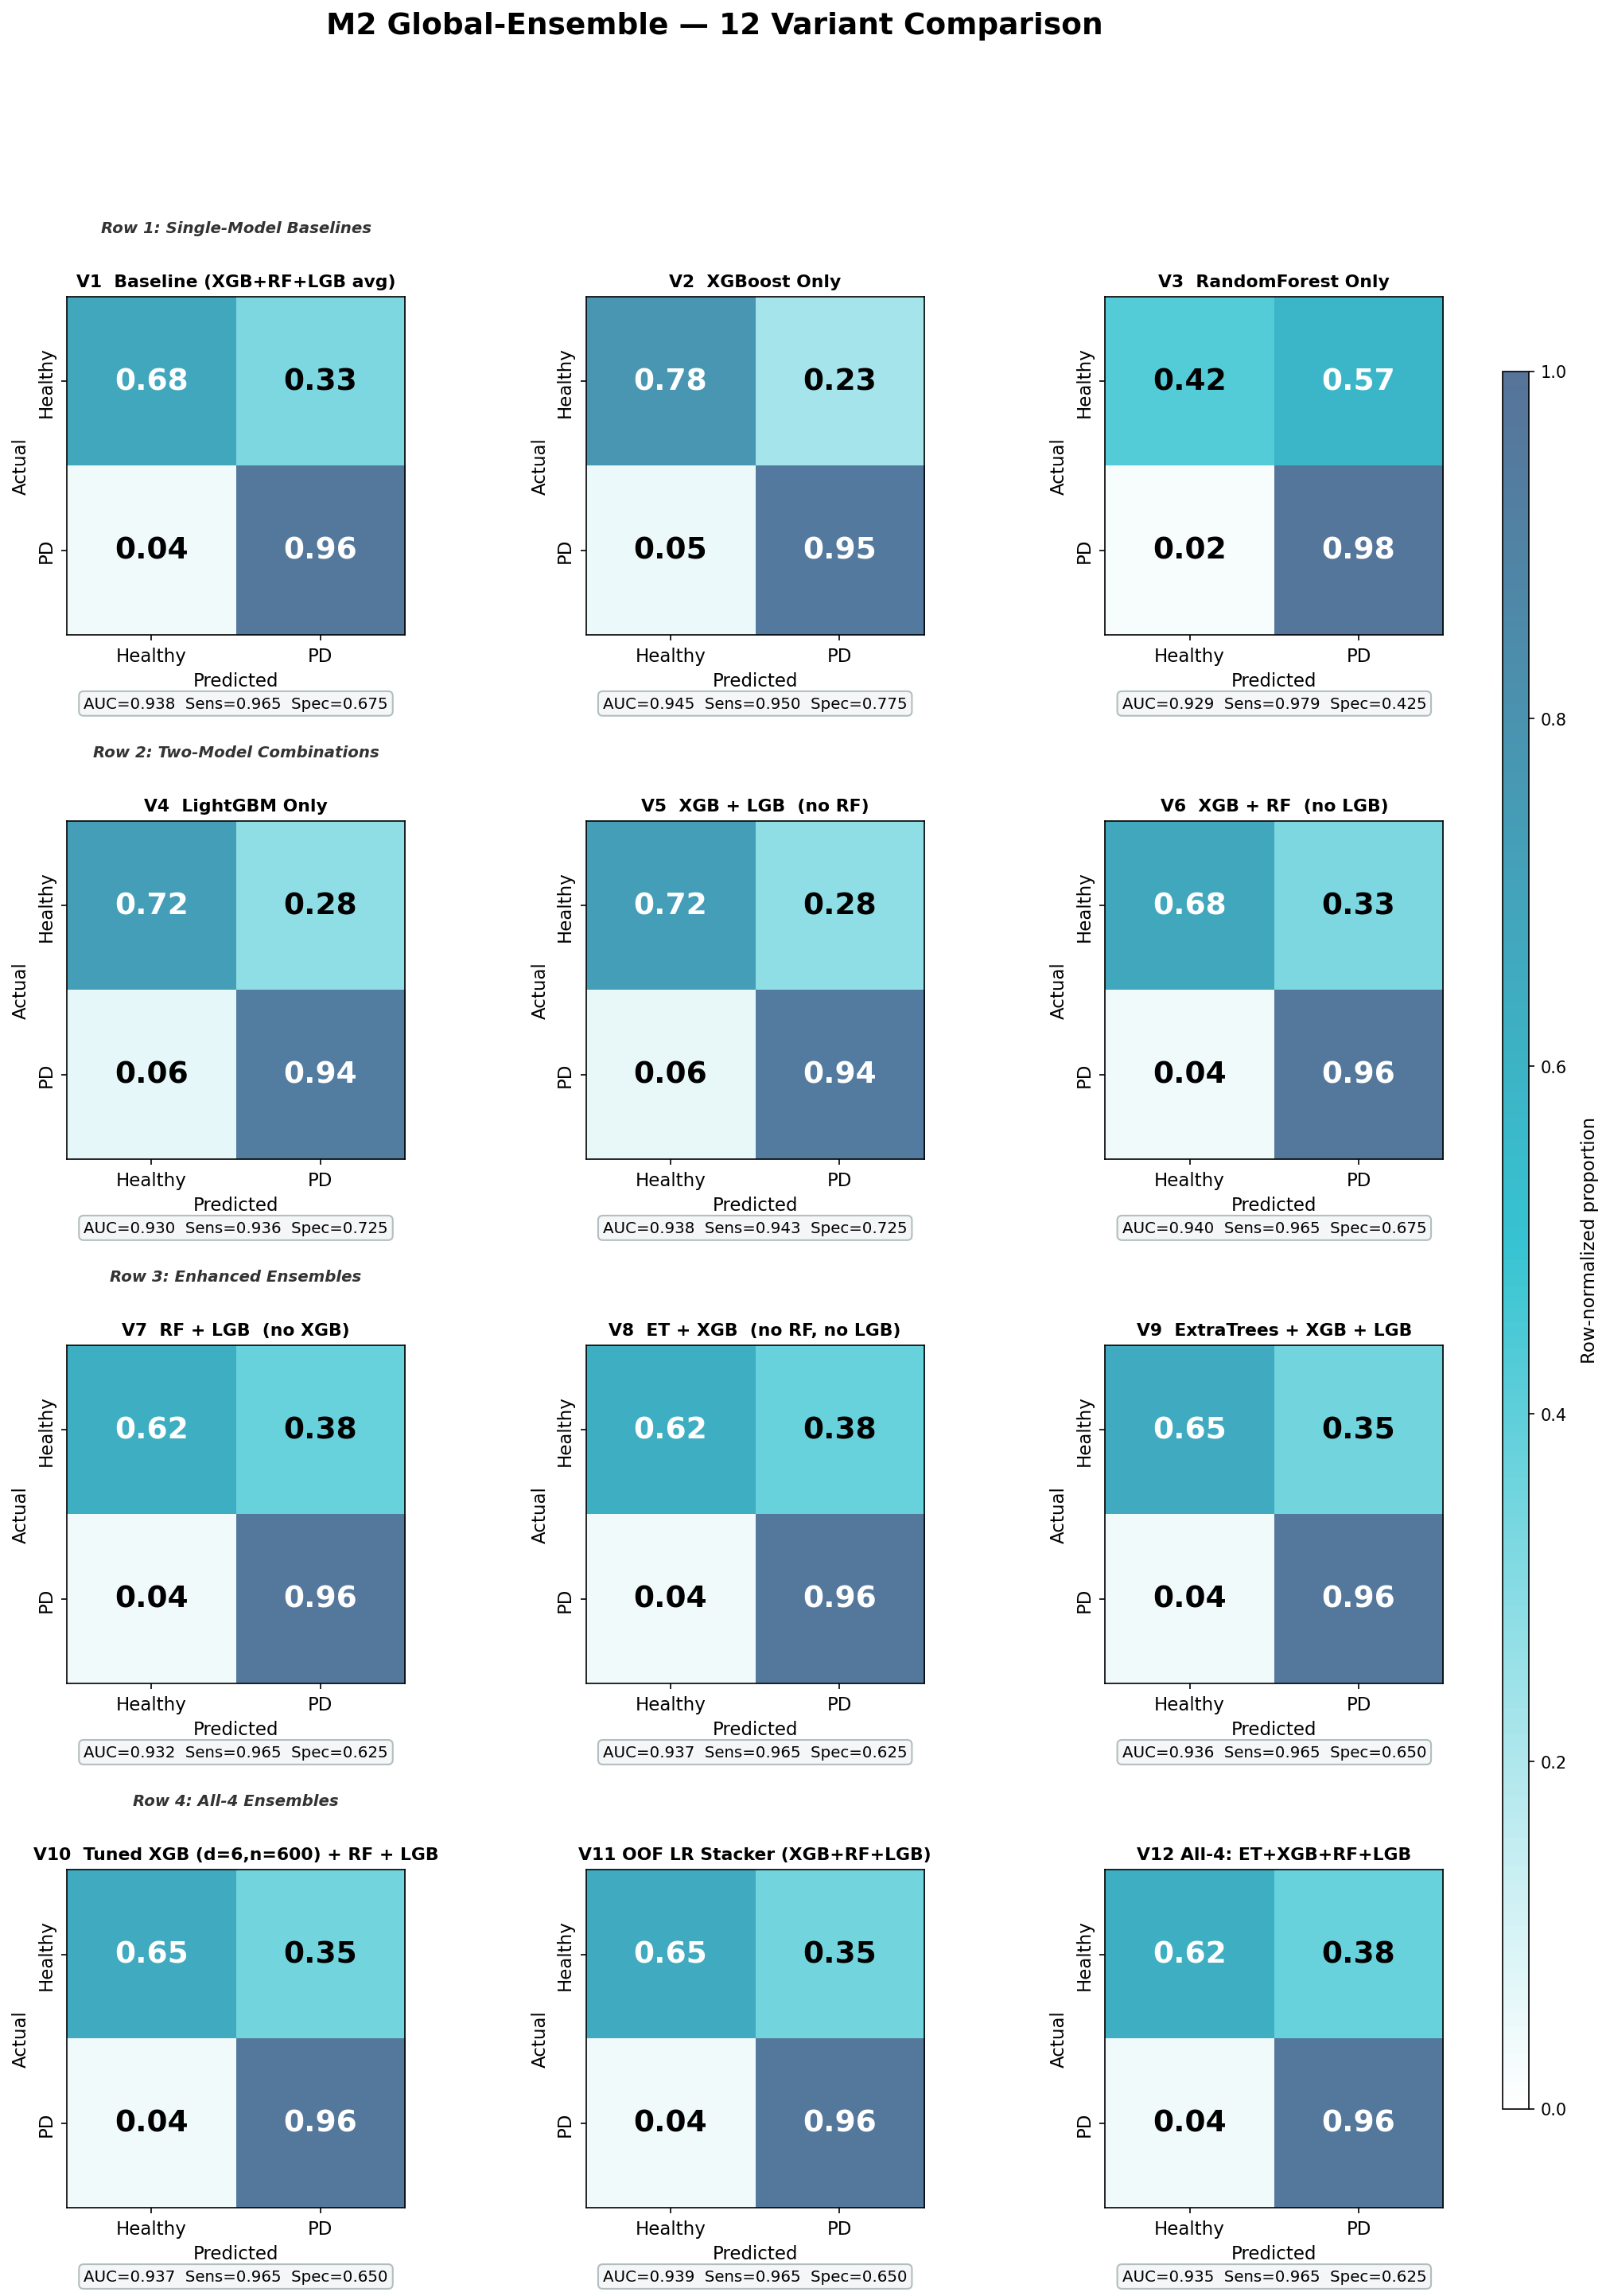

In [ ]:
"""
============================================================
  m2 GLOBAL-ENSEMBLE VARIANT COMPARISON  (12 Variants)
  no_UPDRS  ·  Final_Model  ·  parallel version
============================================================

PURPOSE
-------
Tests 12 variants of the m2 Global Ensemble model across four rows:
  • Row 1 — Single-model baselines  (isolate individual model performance)
  • Row 2 — Two-model combinations  (find the best pair)
  • Row 3 — Enhanced ensembles      (new combiner strategies)
  • Row 4 — Additional variants     (LGB only, ET only, 4-model ensemble)

VARIANT MAP  (4 cols × 3 rows)
------------------------------------------------------
Row 1 — Single-model baselines
  V1   Baseline: XGB + RF + LGB  (equal soft-vote average)  [current]
  V2   XGBoost only
  V3   RandomForest only
  V4   LightGBM only

Row 2 — Two-model combinations
  V5   XGB + LGB   (no RF)
  V6   XGB + RF    (no LGB)
  V7   RF  + LGB   (no XGB)
  V8   ET  + XGB   (no RF, no LGB)

Row 3 — Enhanced ensembles
  V9   ExtraTrees + XGB + LGB        (replace RF with ExtraTrees)
  V10   Tuned XGB (max_depth 4→6, n_estimators 400→600) + RF + LGB
  V11  OOF-Trained LR Stacker on XGB + RF + LGB
  V12  All-4 Ensemble (ET + XGB + RF + LGB)

DATA  (no_UPDRS)
----
  Train : 50%-sparse (Final_Model/Train/Sparse_Matrix_Min50_Train.csv) — all visit rows
  Test  : 50%-sparse (Final_Model/Test/Sparse_Matrix_Min50_Test.csv)   — all visit rows
  Features: the 30 non-motor features + age + sex (handedness removed from the data in Make_Datasets)
  CV    : PATNO-level GroupKFold (5 splits × 3 repeats) for V11 stacker OOF
  Eval  : predictions aggregated to PATNO level before all metrics

CHANGES FROM THE with_UPDRS VERSION
-----------------------------------
  Models, variants, metrics and plots are unchanged. Only:
    1. Paths point at no_UPDRS/Final_Model and its Min50 files.
    2. "Hand" is no longer in the data; EXCLUDE_COLS is kept as a safeguard.
    3. Parallel execution (joblib):
       • The original fitted several identical models under different names
         (xgb0/xgb1, rf0/rf2, lgb0/lgb3, et7/et8/et11 — same settings, same
         random_state, same data). Each distinct model is now fitted ONCE and
         the five distinct models are fitted in parallel. Predictions are
         identical; every variant is combined exactly as before.
       • The 15 V11 OOF folds run in parallel, with RF/LGB inside each fold
         set to n_jobs=1 so the folds do not oversubscribe the CPU.
       Set N_JOBS = 1 for serial execution.

HOW TO RUN
----------
    Run this cell with the Python 3.13 (Anaconda base) kernel.
    Outputs → Final_Model/M2_Variant_Results/
"""

import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from joblib import Parallel, delayed

from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    roc_auc_score, confusion_matrix, f1_score, balanced_accuracy_score,
    brier_score_loss
)
from xgboost import XGBClassifier

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print("⚠ LightGBM not installed — LGB variants will be skipped or approximated.")

warnings.filterwarnings("ignore")

# ═════════════════════════════════════════════════════════════════════════════
#  CONFIGURATION
# ═════════════════════════════════════════════════════════════════════════════
BASE_DIR   = os.getcwd()   # run from the repository root
TRAIN_PATH = os.path.join(BASE_DIR, "Train", "Sparse_Matrix_Min50_Train.csv")
TEST_PATH  = os.path.join(BASE_DIR, "Test",  "Sparse_Matrix_Min50_Test.csv")

RESULT_DIR   = os.path.join(BASE_DIR, "M2_Variant_Results")
RANDOM_STATE = 42
N_SPLITS     = 5
N_REPEATS    = 3

# Columns never used as features in the no_UPDRS final model
EXCLUDE_COLS = ["Hand"]

# Parallelism: -1 = all cores, 1 = serial. "threading" works inside Jupyter on
# Windows with functions defined in the notebook; the tree libraries release the GIL.
N_JOBS           = -1
PARALLEL_BACKEND = "threading"

os.makedirs(RESULT_DIR, exist_ok=True)


# ═════════════════════════════════════════════════════════════════════════════
#  DATA LOADING
# ═════════════════════════════════════════════════════════════════════════════

def load_data(path: str):
    """Load visit-level 50%-sparse CSV. Returns (X, y, patno_array)."""
    df = pd.read_csv(path)
    df = df.rename(columns={"Age": "age", "Sex": "sex"})
    df["label"] = df["APPRDX"].map({1: 1, 2: 0})
    df["sex"]   = df["sex"].map({1: 0, 2: 1})
    patno_array = df["PATNO"].values
    drop_cols   = ["PATNO", "APPRDX"] + (["EVENT_ID"] if "EVENT_ID" in df.columns else [])
    drop_cols  += [c for c in EXCLUDE_COLS if c in df.columns]
    X = df.drop(columns=drop_cols + ["label"])
    y = df["label"].values
    return X, y, patno_array


def detect_cat_idx(X: pd.DataFrame, max_unique: int = 6,
                   min_int_frac: float = 0.8) -> list:
    cat_idx = []
    for i, col in enumerate(X.columns):
        s = X[col].dropna()
        if len(s) == 0:
            continue
        if s.nunique() <= max_unique and (s == s.round()).mean() >= min_int_frac:
            cat_idx.append(i)
    return cat_idx


# ═════════════════════════════════════════════════════════════════════════════
#  PATNO-LEVEL HELPERS
# ═════════════════════════════════════════════════════════════════════════════

def grouped_kfold_splits(patno_array, y, n_splits=N_SPLITS,
                          n_repeats=N_REPEATS, random_state=RANDOM_STATE):
    """Yield (repeat, fold, tr_idx, va_idx) with PATNO-level GroupKFold."""
    rng = np.random.RandomState(random_state)
    unique_patnos = np.unique(patno_array)
    for repeat in range(n_repeats):
        shuffled     = rng.permutation(unique_patnos)
        patno_to_grp = {p: i for i, p in enumerate(shuffled)}
        group_arr    = np.array([patno_to_grp[p] for p in patno_array])
        gkf = GroupKFold(n_splits=n_splits)
        for fold, (tr_idx, va_idx) in enumerate(gkf.split(
                np.zeros(len(patno_array)), y, group_arr)):
            yield repeat, fold, tr_idx, va_idx


def aggregate_to_patno(patno_array, probs):
    """Average visit-level probs → one value per PATNO."""
    df  = pd.DataFrame({"patno": patno_array, "prob": probs})
    agg = df.groupby("patno")["prob"].mean()
    return agg.index.values, agg.values


def patno_labels(patno_array, y):
    df = pd.DataFrame({"patno": patno_array, "label": y})
    return df.groupby("patno")["label"].first()


# ═════════════════════════════════════════════════════════════════════════════
#  MODEL BUILDERS
# ═════════════════════════════════════════════════════════════════════════════

def make_xgb(spw: float, deep: bool = False) -> XGBClassifier:
    return XGBClassifier(
        max_depth        = 6 if deep else 4,
        n_estimators     = 600 if deep else 400,
        learning_rate    = 0.05,
        subsample        = 0.8,
        colsample_bytree = 0.8,
        scale_pos_weight = spw,
        eval_metric      = "logloss",
        random_state     = RANDOM_STATE,
        n_jobs           = 1,   # deterministic: random_state=42 only reproducible with n_jobs=1
    )


def make_rf(n_est: int = 400, n_jobs: int = -1) -> RandomForestClassifier:
    return RandomForestClassifier(n_estimators=n_est, class_weight="balanced",
                                   random_state=RANDOM_STATE, n_jobs=n_jobs)


def make_et(n_est: int = 400, n_jobs: int = -1) -> ExtraTreesClassifier:
    return ExtraTreesClassifier(n_estimators=n_est, class_weight="balanced",
                                 random_state=RANDOM_STATE, n_jobs=n_jobs)


def make_lgb(spw: float, cat_idx: list, n_jobs: int = -1):
    if not HAS_LGBM:
        return None
    return LGBMClassifier(n_estimators=400, learning_rate=0.05, max_depth=4,
                           scale_pos_weight=spw, random_state=RANDOM_STATE,
                           n_jobs=n_jobs, verbose=-1)


def _fit(model, X, y, **fit_kw):
    """Fit one model (used as a parallel job)."""
    return model.fit(X, y, **fit_kw)


# ═════════════════════════════════════════════════════════════════════════════
#  V11 — OOF STACKER  (PATNO-level GroupKFold, folds in parallel)
# ═════════════════════════════════════════════════════════════════════════════

def _oof_stacker_fold(X_train_raw, y_train, tr_idx, va_idx, spw, cat_idx):
    """One fold of the V11 OOF loop — same computation as the serial version."""
    Xtr, Xva  = X_train_raw[tr_idx], X_train_raw[va_idx]
    ytr       = y_train[tr_idx]

    imputer  = SimpleImputer(strategy="mean")
    Xtr_imp  = imputer.fit_transform(Xtr)
    Xva_imp  = imputer.transform(Xva)

    xgb_f = make_xgb(spw); xgb_f.fit(Xtr, ytr)
    p_xgb = xgb_f.predict_proba(Xva)[:, 1]

    rf_f = make_rf(n_jobs=1); rf_f.fit(Xtr_imp, ytr)
    p_rf = rf_f.predict_proba(Xva_imp)[:, 1]

    p_lgb = None
    if HAS_LGBM:
        lgb_f = make_lgb(spw, cat_idx, n_jobs=1)
        cfp   = cat_idx if cat_idx else "auto"
        lgb_f.fit(Xtr_imp, ytr, categorical_feature=cfp)
        p_lgb = lgb_f.predict_proba(Xva_imp)[:, 1]
    return va_idx, p_xgb, p_rf, p_lgb


def compute_oof_stacker(X_train_raw: np.ndarray, y_train: np.ndarray,
                        patno_train: np.ndarray, spw: float,
                        cat_idx: list) -> dict:
    """
    PATNO-level GroupKFold OOF stacker.
    All visits of the same patient stay in the same fold.
    Visit-level OOF probs are averaged to PATNO level before fitting stacker.
    """
    n = len(X_train_raw)
    oof_xgb_sum   = np.zeros(n);  oof_xgb_cnt = np.zeros(n)
    oof_rf_sum    = np.zeros(n);  oof_rf_cnt  = np.zeros(n)
    oof_lgb_sum   = np.zeros(n);  oof_lgb_cnt = np.zeros(n)

    splits = [(tr, va) for _, _, tr, va in grouped_kfold_splits(patno_train, y_train)]
    print(f"  [V11 OOF] PATNO-level GroupKFold "
          f"({N_SPLITS} folds × {N_REPEATS} repeats) — {len(splits)} folds in parallel...")
    t0 = time.time()
    res = Parallel(n_jobs=N_JOBS, backend=PARALLEL_BACKEND, verbose=5)(
        delayed(_oof_stacker_fold)(X_train_raw, y_train, tr, va, spw, cat_idx)
        for tr, va in splits)
    for va_idx, p_xgb, p_rf, p_lgb in res:
        oof_xgb_sum[va_idx] += p_xgb; oof_xgb_cnt[va_idx] += 1
        oof_rf_sum[va_idx]  += p_rf;  oof_rf_cnt[va_idx]  += 1
        if p_lgb is not None:
            oof_lgb_sum[va_idx] += p_lgb; oof_lgb_cnt[va_idx] += 1
    print(f"    OOF done in {time.time() - t0:.0f}s")

    oof_xgb = oof_xgb_sum / np.where(oof_xgb_cnt > 0, oof_xgb_cnt, 1)
    oof_rf  = oof_rf_sum  / np.where(oof_rf_cnt  > 0, oof_rf_cnt,  1)
    oof_lgb = oof_lgb_sum / np.where(oof_lgb_cnt > 0, oof_lgb_cnt, 1)

    patnos_tr, xgb_p = aggregate_to_patno(patno_train, oof_xgb)
    _,          rf_p  = aggregate_to_patno(patno_train, oof_rf)
    _,          lgb_p = aggregate_to_patno(patno_train, oof_lgb)
    y_patno = patno_labels(patno_train, y_train).loc[patnos_tr].values

    X_oof   = np.column_stack([xgb_p, rf_p, lgb_p if HAS_LGBM else xgb_p])
    stacker = LogisticRegression(C=0.5, max_iter=500, random_state=RANDOM_STATE)
    stacker.fit(X_oof, y_patno)
    coef = stacker.coef_[0]
    print(f"    Learned weights → XGB={coef[0]:.3f}  RF={coef[1]:.3f}  "
          f"LGB={coef[2]:.3f}")

    imputer_full = SimpleImputer(strategy="mean")
    X_imp_full   = imputer_full.fit_transform(X_train_raw)

    xgb_final = make_xgb(spw); xgb_final.fit(X_train_raw, y_train)
    rf_final  = make_rf();      rf_final.fit(X_imp_full,   y_train)
    lgb_final = None
    if HAS_LGBM:
        lgb_final = make_lgb(spw, cat_idx)
        cfp = cat_idx if cat_idx else "auto"
        lgb_final.fit(X_imp_full, y_train, categorical_feature=cfp)

    return {"stacker": stacker, "imputer": imputer_full,
            "xgb": xgb_final, "rf": rf_final, "lgb": lgb_final}


def predict_oof_stacker(bundle: dict, X_te_raw: np.ndarray,
                        patno_test: np.ndarray):
    """Predict with V11 stacker, return (patnos, patno-level probs)."""
    X_imp = bundle["imputer"].transform(X_te_raw)
    p_xgb = bundle["xgb"].predict_proba(X_te_raw)[:, 1]
    p_rf  = bundle["rf"].predict_proba(X_imp)[:, 1]
    p_lgb = (bundle["lgb"].predict_proba(X_imp)[:, 1]
             if bundle["lgb"] is not None else p_xgb)
    patnos, xgb_p = aggregate_to_patno(patno_test, p_xgb)
    _,       rf_p  = aggregate_to_patno(patno_test, p_rf)
    _,       lgb_p = aggregate_to_patno(patno_test, p_lgb)
    X_stack = np.column_stack([xgb_p, rf_p, lgb_p])
    return patnos, bundle["stacker"].predict_proba(X_stack)[:, 1]


# ═════════════════════════════════════════════════════════════════════════════
#  METRICS & PLOTTING
# ═════════════════════════════════════════════════════════════════════════════

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    cm     = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return dict(
        AUC               = roc_auc_score(y_true, y_prob),
        Sensitivity       = tp / (tp + fn) if (tp + fn) > 0 else 0.0,
        Specificity       = tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        F1                = f1_score(y_true, y_pred, zero_division=0),
        Balanced_Accuracy = balanced_accuracy_score(y_true, y_pred),
        Brier             = brier_score_loss(y_true, y_prob),
        TP=tp, FP=fp, TN=tn, FN=fn, confusion_matrix=cm,
    )


def plot_cm(cm, title, save_path, subtitle=None):
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    cmap = LinearSegmentedColormap.from_list(
        "custom_cm", [(0.0, "#FFFFFF"), (0.5, "#36C3D1"), (1.0, "#577399")])
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=1, aspect="equal")
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_ticks(np.linspace(0, 1, 6))
    cbar.ax.tick_params(labelsize=10)
    thresh = 0.55
    for i in range(2):
        for j in range(2):
            color = "white" if cm_norm[i, j] > thresh else "black"
            ax.text(j, i, f"{cm_norm[i, j]:.2f}",
                    ha="center", va="center",
                    fontsize=22, fontweight="bold", color=color)
    labels = ["Healthy", "PD"]
    ax.set_xticks([0, 1]);  ax.set_xticklabels(labels, fontsize=12)
    ax.set_yticks([0, 1]);  ax.set_yticklabels(labels, fontsize=12, rotation=90, va="center")
    ax.set_xlabel("Predicted", fontsize=13, labelpad=8)
    ax.set_ylabel("Actual",    fontsize=13, labelpad=8)
    ax.set_title(title if not subtitle else f"{title}\n{subtitle}",
                 fontsize=12, fontweight="bold", pad=10)
    plt.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    svg_path = os.path.splitext(save_path)[0] + ".svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.close(fig)


def plot_comparison_grid(variants_results, save_path):
    ncols, nrows = 3, 4
    cmap = LinearSegmentedColormap.from_list(
        "custom_cm", [(0.0, "#FFFFFF"), (0.5, "#36C3D1"), (1.0, "#577399")])
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5.0, nrows * 5.2))
    fig.suptitle("M2 Global-Ensemble — 12 Variant Comparison",
                 fontsize=18, fontweight="bold", y=0.995)
    row_labels = {
        0: "Row 1: Single-Model Baselines",
        3: "Row 2: Two-Model Combinations",
        6: "Row 3: Enhanced Ensembles",
        9: "Row 4: All-4 Ensembles",
    }
    for idx, (label, met, _) in enumerate(variants_results):
        row_i, col_i = divmod(idx, ncols)
        ax = axes[row_i, col_i]
        cm = met["confusion_matrix"]
        cm_norm = cm / cm.sum(axis=1, keepdims=True)
        im = ax.imshow(cm_norm, cmap=cmap, vmin=0, vmax=1, aspect="equal")
        thresh = 0.55
        for i in range(2):
            for j in range(2):
                color = "white" if cm_norm[i, j] > thresh else "black"
                ax.text(j, i, f"{cm_norm[i, j]:.2f}",
                        ha="center", va="center",
                        fontsize=18, fontweight="bold", color=color)
        ax.set_xticks([0, 1]);  ax.set_xticklabels(["Healthy", "PD"], fontsize=11)
        ax.set_yticks([0, 1]);  ax.set_yticklabels(["Healthy", "PD"], fontsize=11, rotation=90, va="center")
        ax.set_xlabel("Predicted", fontsize=11, labelpad=4)
        ax.set_ylabel("Actual",    fontsize=11, labelpad=4)
        ax.set_title(label, fontsize=10.5, fontweight="bold", pad=6)
        ann = (f"AUC={met['AUC']:.3f}  Sens={met['Sensitivity']:.3f}  "
               f"Spec={met['Specificity']:.3f}")
        ax.text(0.5, -0.18, ann, transform=ax.transAxes,
                ha="center", va="top", fontsize=9.5,
                bbox=dict(boxstyle="round,pad=0.3", fc="#f4f6f7",
                          ec="#aab7b8", alpha=0.9))
        if idx in row_labels:
            ax.text(0.5, 1.18, row_labels[idx], transform=ax.transAxes,
                    ha="center", va="bottom", fontsize=9.5,
                    color="#333333", style="italic", fontweight="bold")
    fig.subplots_adjust(right=0.92, hspace=0.55, wspace=0.35)
    cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
    cbar = fig.colorbar(im, cax=cbar_ax)
    cbar.set_ticks(np.linspace(0, 1, 6))
    cbar.ax.tick_params(labelsize=10)
    cbar.set_label("Row-normalized proportion", fontsize=11, labelpad=8)
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    svg_path = os.path.splitext(save_path)[0] + ".svg"
    fig.savefig(svg_path, format="svg", bbox_inches="tight")
    plt.close(fig)
    print(f"  ✓ Comparison grid saved → {save_path}")
    try:
        from IPython.display import Image as _Img, display as _disp
        _disp(_Img(save_path))
    except Exception:
        pass


def print_summary_table(variants_results):
    h = (f"{'Variant':<42} {'AUC':>7} {'Sens':>7} {'Spec':>7} {'F1':>7} "
         f"{'BalAcc':>8} {'Brier':>7}")
    sections = {0: "Single-Model Baselines", 4: "Two-Model Combinations",
                8: "Enhanced & Extended Ensembles"}
    print("\n" + "═" * len(h))
    print("  m2 VARIANT RESULTS (12 variants)")
    print("═" * len(h))
    print(h)
    for idx, (label, met, _) in enumerate(variants_results):
        if idx in sections:
            print(f"\n  ── {sections[idx]} ──")
        print(f"  {label:<40} {met['AUC']:>7.4f} {met['Sensitivity']:>7.4f} "
              f"{met['Specificity']:>7.4f} {met['F1']:>7.4f} "
              f"{met['Balanced_Accuracy']:>8.4f} {met['Brier']:>7.4f}")
    print("\n" + "═" * len(h))


# ═════════════════════════════════════════════════════════════════════════════
#  MAIN
# ═════════════════════════════════════════════════════════════════════════════

def main():
    t_start = time.time()
    print("\n🔷 m2 VARIANT COMPARISON (12 Variants) — STARTING\n")

    print("  Loading data...")
    X_train, y_train, patno_train = load_data(TRAIN_PATH)
    X_test,  y_test,  patno_test  = load_data(TEST_PATH)
    n_train_p = len(np.unique(patno_train))
    n_test_p  = len(np.unique(patno_test))
    print(f"    Train: {X_train.shape}  PD={y_train.sum()}  "
          f"Healthy={(y_train==0).sum()}  ({n_train_p} patients)")
    print(f"    Test:  {X_test.shape}   PD={y_test.sum()}  "
          f"Healthy={(y_test==0).sum()}  ({n_test_p} patients)")
    print(f"    Excluded columns: {', '.join(EXCLUDE_COLS)}")
    print(f"    CV strategy: PATNO-level GroupKFold({N_SPLITS}) × {N_REPEATS} repeats")
    print(f"    Parallel: n_jobs={N_JOBS}, backend={PARALLEL_BACKEND}")

    neg = (y_train == 0).sum();  pos = (y_train == 1).sum()
    spw = neg / pos
    print(f"    Class ratio → scale_pos_weight = {spw:.3f}")

    cat_idx = detect_cat_idx(X_train)
    print(f"    Categorical feature indices: {len(cat_idx)} detected")

    X_tr_np  = X_train.values
    X_te_np  = X_test.values

    shared_imputer = SimpleImputer(strategy="mean")
    X_tr_imp = shared_imputer.fit_transform(X_tr_np)
    X_te_imp = shared_imputer.transform(X_te_np)

    pat_lbl = patno_labels(patno_test, y_test)

    # ── Fit every DISTINCT base model once, in parallel ──────────────────────
    # (the original refitted identical copies: xgb0=xgb1, rf0=rf2, lgb0=lgb3,
    #  et7=et8=et11 — same settings, same random_state, same data)
    print("\n  Fitting the distinct base models in parallel "
          "(XGB, deep XGB, RF, ET" + (", LGB" if HAS_LGBM else "") + ")...")
    t0 = time.time()
    jobs = {
        "xgb":      (make_xgb(spw),            X_tr_np,  {}),
        "xgb_deep": (make_xgb(spw, deep=True), X_tr_np,  {}),
        "rf":       (make_rf(),                X_tr_imp, {}),
        "et":       (make_et(),                X_tr_imp, {}),
    }
    if HAS_LGBM:
        jobs["lgb"] = (make_lgb(spw, cat_idx), X_tr_imp,
                       {"categorical_feature": cat_idx if cat_idx else "auto"})
    fitted = dict(zip(jobs, Parallel(n_jobs=N_JOBS, backend=PARALLEL_BACKEND)(
        delayed(_fit)(m, Xf, y_train, **kw) for m, Xf, kw in jobs.values())))
    print(f"    done in {time.time() - t0:.0f}s")

    xgb0 = xgb1 = fitted["xgb"]
    rf0  = rf2  = fitted["rf"]
    et7  = et8  = et11 = fitted["et"]
    xgb9 = fitted["xgb_deep"]
    lgb0 = lgb3 = fitted.get("lgb")

    variants = []

    def run(label, tag, visit_probs_te):
        """Aggregate visit probs → PATNO, compute metrics, plot CM."""
        patnos, pprobs = aggregate_to_patno(patno_test, visit_probs_te)
        y_p = pat_lbl.loc[patnos].values
        met = compute_metrics(y_p, pprobs)
        variants.append((label, met, tag))
        plot_cm(met["confusion_matrix"], label,
                os.path.join(RESULT_DIR, f"cm_{tag}.png"),
                subtitle=(f"AUC={met['AUC']:.3f}  "
                          f"Sens={met['Sensitivity']:.3f}  "
                          f"Spec={met['Specificity']:.3f}"))
        print(f"    AUC={met['AUC']:.4f}  Sens={met['Sensitivity']:.4f}  "
              f"Spec={met['Specificity']:.4f}  "
              f"BalAcc={met['Balanced_Accuracy']:.4f}  "
              f"Brier={met['Brier']:.4f}")

    # ── ROW 1: Single-model baselines ────────────────────────────────────────
    print("\n  ── ROW 1: Single-Model Baselines ──")

    print("\n  [V1] Baseline — XGB + RF + LGB  (equal average)")
    if HAS_LGBM:
        p_v1 = np.mean([xgb0.predict_proba(X_te_np)[:, 1],
                         rf0.predict_proba(X_te_imp)[:, 1],
                         lgb0.predict_proba(X_te_imp)[:, 1]], axis=0)
    else:
        p_v1 = np.mean([xgb0.predict_proba(X_te_np)[:, 1],
                         rf0.predict_proba(X_te_imp)[:, 1]], axis=0)
    run("V1  Baseline (XGB+RF+LGB avg)", "v1_baseline", p_v1)

    print("\n  [V2] XGBoost only")
    run("V2  XGBoost Only", "v2_xgb_only", xgb1.predict_proba(X_te_np)[:, 1])

    print("\n  [V3] RandomForest only")
    run("V3  RandomForest Only", "v3_rf_only", rf2.predict_proba(X_te_imp)[:, 1])

    print("\n  [V4] LightGBM only  (NEW)")
    if HAS_LGBM:
        p_lgb3 = lgb3.predict_proba(X_te_imp)[:, 1]
    else:
        p_lgb3 = xgb1.predict_proba(X_te_np)[:, 1]   # fallback if no LGBM
    run("V4  LightGBM Only", "v4_lgb_only", p_lgb3)

    # ── ROW 2: Two-model combinations ────────────────────────────────────────
    print("\n  ── ROW 2: Two-Model Combinations ──")

    # Shared predictions
    p_xgb_te = xgb0.predict_proba(X_te_np)[:, 1]
    p_rf_te  = rf0.predict_proba(X_te_imp)[:, 1]
    p_lgb_te = (lgb0.predict_proba(X_te_imp)[:, 1]
                if lgb0 is not None else p_xgb_te)

    print("\n  [V5] XGB + LGB  (no RF)")
    p_v5 = (p_xgb_te + p_lgb_te) / 2.0
    run("V5  XGB + LGB  (no RF)", "v5_xgb_lgb", p_v5)

    print("\n  [V6] XGB + RF  (no LGB)")
    run("V6  XGB + RF  (no LGB)", "v6_xgb_rf", (p_xgb_te + p_rf_te) / 2.0)

    print("\n  [V7] RF + LGB  (no XGB)")
    p_v7 = (p_rf_te + p_lgb_te) / 2.0
    run("V7  RF + LGB  (no XGB)", "v7_rf_lgb", p_v7)

    print("\n  [V8] ExtraTrees + XGB  (no RF, no LGB)  (NEW)")
    p_et7_te = et7.predict_proba(X_te_imp)[:, 1]
    run("V8  ET + XGB  (no RF, no LGB)", "v8_et_xgb", (p_et7_te + p_xgb_te) / 2.0)

    # ── ROW 3: Enhanced ensembles ─────────────────────────────────────────────
    print("\n  ── ROW 3: Enhanced & Extended Ensembles ──")

    print("\n  [V9] ExtraTrees + XGB + LGB")
    p_et8_te = et8.predict_proba(X_te_imp)[:, 1]
    p_v9 = ((p_et8_te + p_xgb_te + p_lgb_te) / 3.0
            if HAS_LGBM else (p_et8_te + p_xgb_te) / 2.0)
    run("V9  ExtraTrees + XGB + LGB", "v9_et_xgb_lgb", p_v9)

    print("\n  [V10] Tuned XGB (depth=6, n=600) + RF + LGB")
    p_xgb9_te = xgb9.predict_proba(X_te_np)[:, 1]
    p_v10 = ((p_xgb9_te + p_rf_te + p_lgb_te) / 3.0
            if HAS_LGBM else (p_xgb9_te + p_rf_te) / 2.0)
    run("V10  Tuned XGB (d=6,n=600) + RF + LGB", "v10_deep_xgb", p_v10)

    print("\n  [V11] OOF LR Stacker on XGB + RF + LGB")
    stk11 = compute_oof_stacker(X_tr_np, y_train, patno_train, spw, cat_idx)
    patnos_v11, probs_v11 = predict_oof_stacker(stk11, X_te_np, patno_test)
    y_v11 = pat_lbl.loc[patnos_v11].values
    met_v11 = compute_metrics(y_v11, probs_v11)
    variants.append(("V11 OOF LR Stacker (XGB+RF+LGB)", met_v11, "v11_oof_stacker"))
    plot_cm(met_v11["confusion_matrix"], "V11 OOF LR Stacker (XGB+RF+LGB)",
            os.path.join(RESULT_DIR, "cm_v11_oof_stacker.png"),
            subtitle=(f"AUC={met_v11['AUC']:.3f}  "
                      f"Sens={met_v11['Sensitivity']:.3f}  "
                      f"Spec={met_v11['Specificity']:.3f}"))
    print(f"    AUC={met_v11['AUC']:.4f}  Sens={met_v11['Sensitivity']:.4f}  "
          f"Spec={met_v11['Specificity']:.4f}  "
          f"BalAcc={met_v11['Balanced_Accuracy']:.4f}  "
          f"Brier={met_v11['Brier']:.4f}")

    print("\n  [V12] All-4 Ensemble — ET + XGB + RF + LGB  (NEW)")
    p_et11_te = et11.predict_proba(X_te_imp)[:, 1]
    if HAS_LGBM:
        p_v12 = (p_et11_te + p_xgb_te + p_rf_te + p_lgb_te) / 4.0
    else:
        p_v12 = (p_et11_te + p_xgb_te + p_rf_te) / 3.0
    run("V12 All-4: ET+XGB+RF+LGB", "v12_all4_ensemble", p_v12)

    # ── Outputs ───────────────────────────────────────────────────────────────
    print("\n  Generating 3×4 comparison grid (12 CMs)...")
    plot_comparison_grid(variants, os.path.join(RESULT_DIR, "m2_variants_comparison.png"))
    print_summary_table(variants)

    rows = []
    for label, met, tag in variants:
        rows.append({
            "Variant":           label,
            "AUC":               round(met["AUC"],               4),
            "Sensitivity":       round(met["Sensitivity"],        4),
            "Specificity":       round(met["Specificity"],        4),
            "F1":                round(met["F1"],                 4),
            "Balanced_Accuracy": round(met["Balanced_Accuracy"],  4),
            "Brier":             round(met["Brier"],              4),
            "TP": met["TP"], "FP": met["FP"],
            "TN": met["TN"], "FN": met["FN"],
        })
    pd.DataFrame(rows).to_csv(
        os.path.join(RESULT_DIR, "m2_variants_metrics.csv"), index=False)

    print(f"\n✅  All outputs saved to: {os.path.abspath(RESULT_DIR)}")
    print("\n  Individual CMs:")
    for _, _, tag in variants:
        print(f"    cm_{tag}.png")
    print(f"\n  Comparison grid : m2_variants_comparison.png  (3×4, 12 CMs)")
    print(f"  Metrics CSV     : m2_variants_metrics.csv")
    print(f"\n  Total time: {(time.time() - t_start) / 60:.1f} min")


if __name__ == "__main__":
    main()
